In [13]:

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR

# For reproducible results
torch.manual_seed(42)
np.random.seed(42)

# 1. Load CIFAR-10 dataset
df = pd.read_csv('cifar-10.csv').dropna()

pixels = torch.tensor(df.iloc[:, :-1].values, dtype=torch.float32)
labels = torch.tensor(df.iloc[:, -1].values, dtype=torch.long)

# Normalize pixels from 0-255 to -1 to 1
pixels = (pixels / 127.5) - 1.0

# 2. Split into training and testing data
dataset = TensorDataset(pixels, labels)

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_set, test_set = torch.utils.data.random_split(
    dataset, [train_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

# 3. Build Feedforward Neural Network
model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.ReLU(),
    nn.Dropout(0.3),

    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.3),

    nn.Linear(256, 128),
    nn.ReLU(),

    nn.Linear(128, 10)
)

# 4. Define loss, optimizer and scheduler
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = CosineAnnealingLR(optimizer, T_max=20)

# 5. Train the model
epochs = 20

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, targets in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += targets.size(0)
        correct += (predicted == targets).sum().item()

    scheduler.step()

    accuracy = 100 * correct / total
    print("Epoch:", epoch + 1,
          "Loss:", round(total_loss / len(train_loader), 4),
          "Accuracy:", round(accuracy, 2), "%")

# 6. Test the model
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, targets in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += targets.size(0)
        correct += (predicted == targets).sum().item()

test_accuracy = 100 * correct / total
print("\nTest Accuracy:", round(test_accuracy, 2), "%")



Epoch: 1 Loss: 1.7795 Accuracy: 36.05 %
Epoch: 2 Loss: 1.6112 Accuracy: 43.06 %
Epoch: 3 Loss: 1.5263 Accuracy: 46.02 %
Epoch: 4 Loss: 1.4679 Accuracy: 48.01 %
Epoch: 5 Loss: 1.4216 Accuracy: 50.02 %
Epoch: 6 Loss: 1.3716 Accuracy: 51.11 %
Epoch: 7 Loss: 1.3256 Accuracy: 52.82 %
Epoch: 8 Loss: 1.2833 Accuracy: 54.13 %
Epoch: 9 Loss: 1.2338 Accuracy: 55.92 %
Epoch: 10 Loss: 1.1889 Accuracy: 57.38 %
Epoch: 11 Loss: 1.1463 Accuracy: 58.76 %
Epoch: 12 Loss: 1.108 Accuracy: 60.46 %
Epoch: 13 Loss: 1.0634 Accuracy: 61.99 %
Epoch: 14 Loss: 1.0193 Accuracy: 63.36 %
Epoch: 15 Loss: 0.9907 Accuracy: 64.21 %
Epoch: 16 Loss: 0.9617 Accuracy: 65.15 %
Epoch: 17 Loss: 0.9321 Accuracy: 66.12 %
Epoch: 18 Loss: 0.91 Accuracy: 66.64 %
Epoch: 19 Loss: 0.902 Accuracy: 67.14 %
Epoch: 20 Loss: 0.8942 Accuracy: 67.43 %

Test Accuracy: 56.9 %


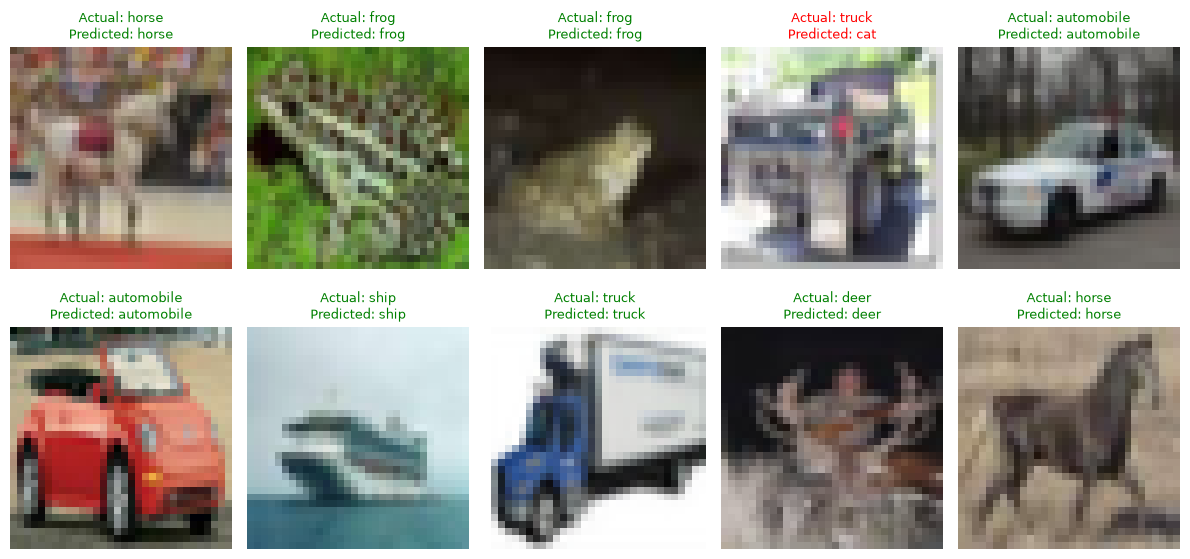

In [12]:

import matplotlib.pyplot as plt

# Get 10 test images
images, targets = next(iter(test_loader))

# Predict their classes
model.eval()
with torch.no_grad():
    outputs = model(images[:10])
    _, predicted = torch.max(outputs, 1)

# Display images with actual and predicted labels
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Convert image from tensor to NumPy format
    img = images[i].reshape(3, 32, 32).permute(1, 2, 0).numpy()

    # Reverse normalization from [-1, 1] to [0, 1]
    img = (img + 1) / 2

    plt.imshow(img)
    plt.title(
        "Actual: " + classes[targets[i].item()] +
        "\nPredicted: " + classes[predicted[i].item()],
        color='green' if targets[i] == predicted[i] else 'red',
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()
